In [1]:
import numpy as np
import torch
import torch.nn as nn
from torch.distributions import Categorical
import matplotlib.pyplot as plt

np.random.seed(0)
torch.manual_seed(0)

In [2]:
class InventoryEnv:
    def __init__(self, max_stock=50, horizon=30):
        self.max_stock, self.horizon = max_stock, horizon
        self.order_sizes = [0, 5, 10, 15, 20]
        self.n_actions = len(self.order_sizes)
        self.obs_dim = 4
        self.price, self.unit_cost = 5.0, 2.0
        self.hold_cost, self.stockout_cost = 0.1, 1.0

    def demand_mean(self, day):
        return 8 + 4 * np.sin(2 * np.pi * day / 7)   # weekly pattern

    def get_obs(self):
        angle = 2 * np.pi * (self.day % 7) / 7
        return np.array([self.stock / self.max_stock, np.sin(angle),
                         np.cos(angle), self.last_demand / 20], dtype=np.float32)

    def reset(self):
        self.day, self.stock, self.last_demand = 0, 20, 8
        return self.get_obs()

    def step(self, action):
        order = self.order_sizes[action]
        self.stock = min(self.stock + order, self.max_stock)
        demand = np.random.poisson(self.demand_mean(self.day))
        sold = min(self.stock, demand)
        lost = demand - sold
        self.stock -= sold
        reward = (self.price * sold - self.unit_cost * order
                  - self.hold_cost * self.stock - self.stockout_cost * lost)
        self.last_demand = demand
        self.day += 1
        done = self.day >= self.horizon
        return self.get_obs(), reward, done

env = InventoryEnv()

## Environment: Retail Inventory Management (Simulated)

A single-product store is simulated over a **30-day episode**. Each morning the manager decides how many units to reorder, **before** seeing that day's demand. The agent must balance lost sales from running out of stock against the cost of ordering too much.

| Component | Description |
|---|---|
| **State** (4 values) | Current stock ÷ 50, sin and cos of the day of the week, previous day's demand ÷ 20 |
| **Actions** (5, discrete) | Order 0, 5, 10, 15 or 20 units |
| **Demand** | Poisson-distributed with mean 8 + 4·sin(2πt/7), a weekly cycle between 4 and 12 units/day |
| **Dynamics** | Orders arrive instantly. Stock is capped at 50 (extra ordered units are wasted). Units sold = min(stock, demand). Unmet demand is lost. |
| **Reward** | 5 × units sold − 2 × units ordered − 0.1 × leftover stock − 1 × units of lost demand |
| **Episode** | 30 days, starting with 20 units in stock. Leftover stock at the end has no value. |

**Objective:** maximise total profit over the episode.

**Why it suits RL:** the best order size depends on current stock, the day of the week and recent demand, and each day's decision affects the stock available on later days. The day of the week is encoded with sin/cos so the agent can learn the weekly pattern.

In [3]:
class ActorCritic(nn.Module):
    def __init__(self, obs_dim, n_actions):
        super().__init__()
        self.actor = nn.Sequential(
            nn.Linear(obs_dim, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, n_actions))
        self.critic = nn.Sequential(
            nn.Linear(obs_dim, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, 1))

    def forward(self, x):
        return Categorical(logits=self.actor(x)), self.critic(x).squeeze(-1)

model = ActorCritic(env.obs_dim, env.n_actions)
optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)

In [4]:
REWARD_SCALE = 0.1   # keeps reward magnitudes small for stable training

def collect_rollout(env, model, n_steps=900):
    obs_l, act_l, logp_l, rew_l, val_l, done_l, ep_returns = [], [], [], [], [], [], []
    obs, ep_ret = env.reset(), 0.0
    for _ in range(n_steps):
        with torch.no_grad():
            dist, value = model(torch.tensor(obs))
            action = dist.sample()
        next_obs, reward, done = env.step(action.item())

        obs_l.append(obs); act_l.append(action); logp_l.append(dist.log_prob(action))
        rew_l.append(reward * REWARD_SCALE); val_l.append(value); done_l.append(float(done))

        ep_ret += reward
        if done:
            ep_returns.append(ep_ret)
            ep_ret, next_obs = 0.0, env.reset()
        obs = next_obs

    batch = {
        "obs": torch.tensor(np.array(obs_l)),
        "actions": torch.stack(act_l),
        "logp": torch.stack(logp_l),
        "rewards": torch.tensor(rew_l, dtype=torch.float32),
        "values": torch.stack(val_l),
        "dones": torch.tensor(done_l),
    }
    return batch, ep_returns

In [5]:
def compute_gae(rewards, values, dones, gamma=0.99, lam=0.95):
    advantages = torch.zeros_like(rewards)
    last = 0.0
    for t in reversed(range(len(rewards))):
        next_value = values[t + 1] if t + 1 < len(rewards) else 0.0
        nonterminal = 1.0 - dones[t]
        delta = rewards[t] + gamma * next_value * nonterminal - values[t]
        last = delta + gamma * lam * nonterminal * last
        advantages[t] = last
    return advantages, advantages + values   # advantages, returns

In [6]:
def ppo_update(model, optimizer, batch, epochs=10, batch_size=128,
               clip=0.2, vf_coef=0.5, ent_coef=0.01):
    n = len(batch["obs"])
    for _ in range(epochs):
        idx = torch.randperm(n)
        for start in range(0, n, batch_size):
            mb = idx[start:start + batch_size]
            dist, value = model(batch["obs"][mb])
            new_logp = dist.log_prob(batch["actions"][mb])
            ratio = (new_logp - batch["logp"][mb]).exp()

            adv = batch["adv"][mb]
            adv = (adv - adv.mean()) / (adv.std() + 1e-8)

            policy_loss = -torch.min(ratio * adv,
                                     ratio.clamp(1 - clip, 1 + clip) * adv).mean()
            value_loss = (batch["returns"][mb] - value).pow(2).mean()
            entropy = dist.entropy().mean()

            loss = policy_loss + vf_coef * value_loss - ent_coef * entropy
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 0.5)
            optimizer.step()

In [7]:
n_updates = 150
history = []

for update in range(n_updates):
    batch, ep_returns = collect_rollout(env, model)
    adv, returns = compute_gae(batch["rewards"], batch["values"], batch["dones"])
    batch["adv"], batch["returns"] = adv, returns
    ppo_update(model, optimizer, batch)

    history.append(np.mean(ep_returns))
    if (update + 1) % 15 == 0:
        print(f"Update {update + 1:3d} | Avg episode profit: {history[-1]:.1f}")

Update  15 | Avg episode profit: 632.8
Update  30 | Avg episode profit: 665.9
Update  45 | Avg episode profit: 659.2
Update  60 | Avg episode profit: 641.5
Update  75 | Avg episode profit: 691.1
Update  90 | Avg episode profit: 675.4
Update 105 | Avg episode profit: 667.2
Update 120 | Avg episode profit: 682.5
Update 135 | Avg episode profit: 708.8
Update 150 | Avg episode profit: 677.5


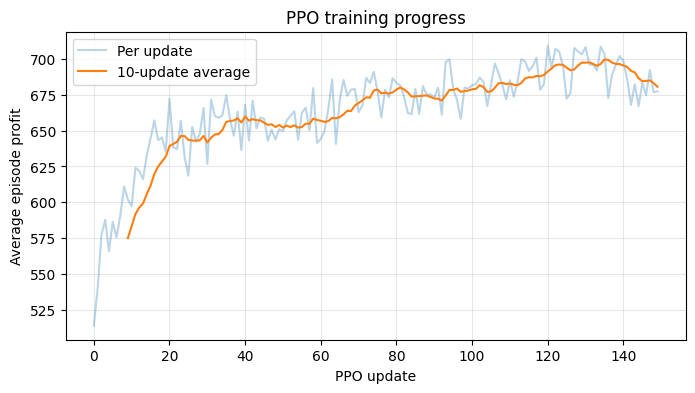

In [8]:
window = 10
smooth = np.convolve(history, np.ones(window) / window, mode="valid")

plt.figure(figsize=(8, 4))
plt.plot(history, alpha=0.3, label="Per update")
plt.plot(range(window - 1, len(history)), smooth, label=f"{window}-update average")
plt.xlabel("PPO update")
plt.ylabel("Average episode profit")
plt.title("PPO training progress")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Random           profit =   492.1 ± 99.3
Fixed (10/day)   profit =   523.3 ± 88.8
Order-up-to 20   profit =   711.6 ± 51.7
PPO              profit =   699.8 ± 56.9


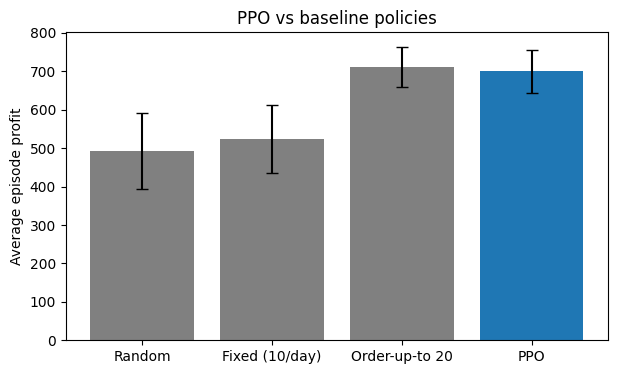

In [9]:
def ppo_policy(obs):
    with torch.no_grad():
        dist, _ = model(torch.tensor(obs))
    return dist.probs.argmax().item()          # greedy action

def random_policy(obs):
    return np.random.randint(env.n_actions)

def fixed_policy(obs):
    return 2                                    # always order 10 units

def order_up_to_policy(obs, target=20):
    stock = obs[0] * env.max_stock
    need = max(0, target - stock)
    return int(np.argmin([abs(o - need) for o in env.order_sizes]))

def evaluate(policy, episodes=200):
    returns = []
    for _ in range(episodes):
        obs, done, total = env.reset(), False, 0.0
        while not done:
            obs, r, done = env.step(policy(obs))
            total += r
        returns.append(total)
    return np.mean(returns), np.std(returns)

policies = {"Random": random_policy, "Fixed (10/day)": fixed_policy,
            "Order-up-to 20": order_up_to_policy, "PPO": ppo_policy}
results = {name: evaluate(p) for name, p in policies.items()}

for name, (m, s) in results.items():
    print(f"{name:16s} profit = {m:7.1f} ± {s:.1f}")

plt.figure(figsize=(7, 4))
plt.bar(results.keys(), [v[0] for v in results.values()],
        yerr=[v[1] for v in results.values()], capsize=4,
        color=["gray", "gray", "gray", "tab:blue"])
plt.ylabel("Average episode profit")
plt.title("PPO vs baseline policies")
plt.show()

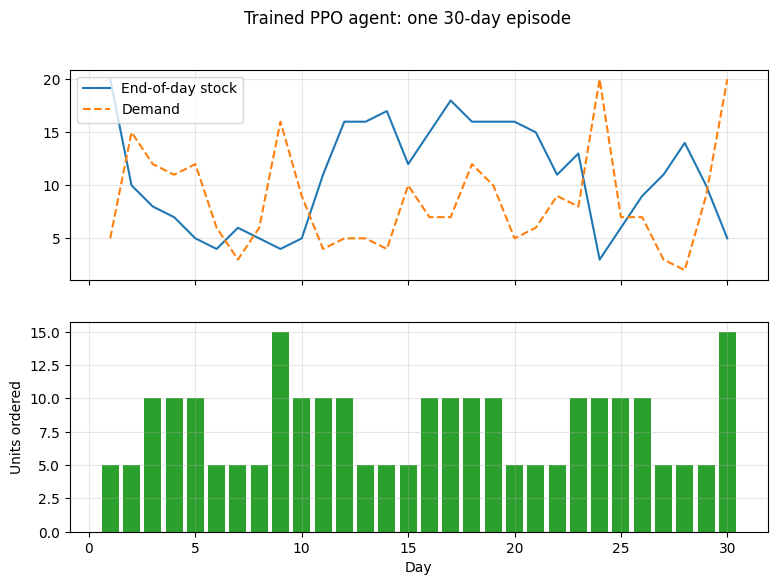

In [10]:
obs, done = env.reset(), False
stock_log, demand_log, order_log = [], [], []

while not done:
    action = ppo_policy(obs)
    obs, _, done = env.step(action)
    stock_log.append(env.stock)
    demand_log.append(env.last_demand)
    order_log.append(env.order_sizes[action])

days = range(1, len(stock_log) + 1)
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].plot(days, stock_log, label="End-of-day stock")
ax[0].plot(days, demand_log, label="Demand", linestyle="--")
ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].bar(days, order_log, color="tab:green")
ax[1].set_ylabel("Units ordered"); ax[1].set_xlabel("Day")
ax[1].grid(alpha=0.3)
plt.suptitle("Trained PPO agent: one 30-day episode")
plt.show()